*   Name : Molemi Molokoane
*   Email : iimillicent02@gmail.com

# Week 6 Assignment: Data Storytelling with Power BI

The dashboard itself is built in **Power BI Desktop** (steps in `Power_BI_Guide.md`). This notebook does two things:
1. Rebuilds the two master CSVs (`olist_sales_master.csv` and `olist_reviews_master.csv`) with the same joins as the class notebook.
2. Calculates the answer to every Group A and Group B question in pandas, so I can check that my Power BI visuals use the right aggregation (Sum vs Average vs Distinct Count).

## 1. Load the Olist Data

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Local copy of the Olist dataset. In Colab, point this at the Drive folder instead.
DATA_DIR = "../Olist Dataset"
OUTPUT_DIR = "power_bi_datasets"
os.makedirs(OUTPUT_DIR, exist_ok=True)

orders = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv")
order_items = pd.read_csv(f"{DATA_DIR}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{DATA_DIR}/olist_products_dataset.csv")
reviews = pd.read_csv(f"{DATA_DIR}/olist_order_reviews_dataset.csv")
geolocation = pd.read_csv(f"{DATA_DIR}/olist_geolocation_dataset.csv")
customers = pd.read_csv(f"{DATA_DIR}/olist_customers_dataset.csv")
translation = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")

for name, df in [("orders", orders), ("order_items", order_items), ("products", products),
                 ("reviews", reviews), ("geolocation", geolocation), ("customers", customers)]:
    print(f"{name:12s} {df.shape[0]:>9,} rows, {df.shape[1]} columns")

# Colours for the reference charts
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b8b7b2"

orders          99,441 rows, 8 columns
order_items    112,650 rows, 7 columns
products        32,951 rows, 9 columns
reviews         99,224 rows, 7 columns
geolocation  1,000,163 rows, 5 columns
customers       99,441 rows, 5 columns


## 2. Build the Master CSVs
Same steps as the class notebook. The geolocation table has many rows per zip prefix, so I average it to one row per prefix before joining. Otherwise every sales row would be duplicated.

In [2]:
geo_dedup = geolocation.groupby("geolocation_zip_code_prefix").agg({
    "geolocation_lat": "mean",
    "geolocation_lng": "mean",
    "geolocation_city": "first",
    "geolocation_state": "first",
}).reset_index()

# Master 1: one row per order item
sales_master = (
    order_items
    .merge(orders, on="order_id", how="left")
    .merge(products[["product_id", "product_category_name", "product_weight_g",
                     "product_length_cm", "product_height_cm", "product_width_cm"]],
           on="product_id", how="left")
    .merge(customers, on="customer_id", how="left")
    .merge(geo_dedup, left_on="customer_zip_code_prefix",
           right_on="geolocation_zip_code_prefix", how="left")
)

# Master 2: one row per review
reviews_master = (
    reviews
    .merge(orders, on="order_id", how="left")
    .merge(customers, on="customer_id", how="left")
)

# A left join must never add rows
assert len(sales_master) == len(order_items)
assert len(reviews_master) == len(reviews)

sales_master.to_csv(f"{OUTPUT_DIR}/olist_sales_master.csv", index=False, encoding="utf-8")
reviews_master.to_csv(f"{OUTPUT_DIR}/olist_reviews_master.csv", index=False, encoding="utf-8")
print("sales_master:  ", sales_master.shape)
print("reviews_master:", reviews_master.shape)

sales_master:   (112650, 28)
reviews_master: (99224, 18)


## 3. Check the Relationship Before Modelling
The assignment suggests linking the tables on `order_id` as a **1-to-many** relationship. That only works if `order_id` is unique on the "1" side.

In [3]:
print("Sales rows per order_id (max):  ", sales_master["order_id"].value_counts().max())
print("Review rows per order_id (max): ", reviews_master["order_id"].value_counts().max())
print("Orders with more than one review:", reviews_master["order_id"].duplicated().sum())
print("Duplicated review_id values:     ", reviews_master["review_id"].duplicated().sum())

Sales rows per order_id (max):   21
Review rows per order_id (max):  3
Orders with more than one review: 551
Duplicated review_id values:      814


`order_id` repeats in **both** tables, so Power BI would create a *many-to-many* relationship, which can double-count. Each question below only needs one table (Group A uses sales, Group B uses reviews), so I **keep the two fact tables separate** in the model, as the assignment allows.

## 4. Group A: Sales and Product Performance
**Revenue** = `price + freight_value`, i.e. what the customer paid at checkout. I keep all order statuses, which matches what Power BI shows by default when no filter is applied.

In [4]:
sales_master["revenue"] = sales_master["price"] + sales_master["freight_value"]
english = dict(zip(translation["product_category_name"], translation["product_category_name_english"]))
sales_master["category_english"] = sales_master["product_category_name"].map(english)

print(f"Total revenue: R$ {sales_master['revenue'].sum():,.2f}")
print(f"Total items:   {len(sales_master):,}")
print(f"Unique orders: {sales_master['order_id'].nunique():,}")

Total revenue: R$ 15,843,553.24
Total items:   112,650
Unique orders: 98,666


### A1. Which state generates the highest revenue?

                   revenue  share_%
customer_state                     
SP              5921678.12     37.4
RJ              2129681.98     13.4
MG              1856161.49     11.7
RS               885826.76      5.6
PR               800935.44      5.1
BA               611506.67      3.9
SC               610213.60      3.9
DF               353229.44      2.2
GO               347706.93      2.2
ES               324801.91      2.1


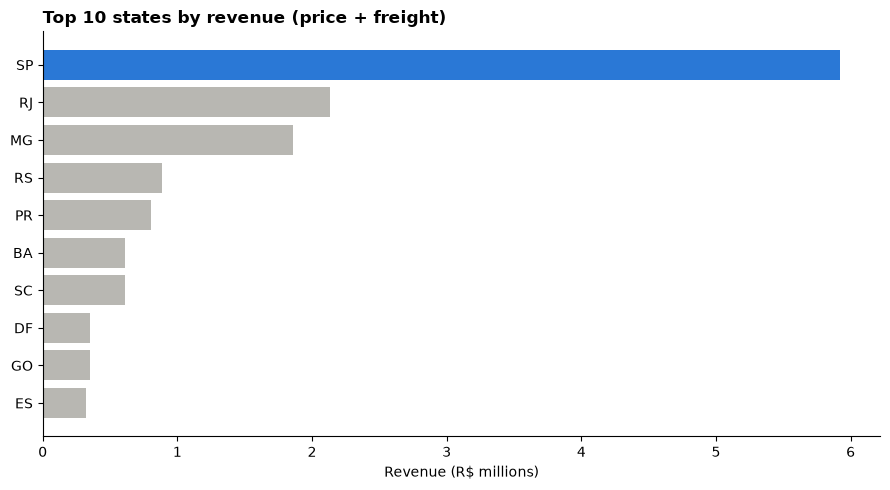

In [5]:
state_revenue = (sales_master.groupby("customer_state")["revenue"].sum()
                 .sort_values(ascending=False))
share = state_revenue / state_revenue.sum() * 100
print(pd.DataFrame({"revenue": state_revenue.round(2), "share_%": share.round(1)}).head(10))

top10 = state_revenue.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10.index, top10.values / 1e6, color=[BLUE if s == "SP" else GREY for s in top10.index])
ax.set_title("Top 10 states by revenue (price + freight)", loc="left", fontweight="bold")
ax.set_xlabel("Revenue (R$ millions)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Answer:** **São Paulo (SP)** by a wide margin: about R$ 5.92M, or 37% of all revenue. That is almost 3× the next state, Rio de Janeiro (RJ, R$ 2.13M), followed by Minas Gerais (MG, R$ 1.86M). The Southeast states dominate Olist's sales.

### A2. Top 10 categories by item count: do they also generate the most revenue?

In [6]:
cat = sales_master.groupby("category_english").agg(
    items=("order_item_id", "size"),
    revenue=("revenue", "sum"),
)
cat["items_rank"] = cat["items"].rank(ascending=False).astype(int)
cat["revenue_rank"] = cat["revenue"].rank(ascending=False).astype(int)
top_items = cat.sort_values("items", ascending=False).head(10)
print(top_items)

top_revenue = set(cat.sort_values("revenue", ascending=False).head(10).index)
print("\nIn top 10 by items but NOT top 10 by revenue:", sorted(set(top_items.index) - top_revenue))
print("In top 10 by revenue but NOT top 10 by items:", sorted(top_revenue - set(top_items.index)))

                       items     revenue  items_rank  revenue_rank
category_english                                                  
bed_bath_table         11115  1241681.72           1             3
health_beauty           9670  1441248.07           2             1
sports_leisure          8641  1156656.48           3             4
furniture_decor         8334   902511.79           4             6
computers_accessories   7827  1059272.40           5             5
housewares              6964   778397.77           6             7
watches_gifts           5991  1305541.61           7             2
telephony               4545   394883.32           8            14
garden_tools            4347   584219.21           9            10
auto                    4235   685384.32          10             9

In top 10 by items but NOT top 10 by revenue: ['telephony']
In top 10 by revenue but NOT top 10 by items: ['cool_stuff']


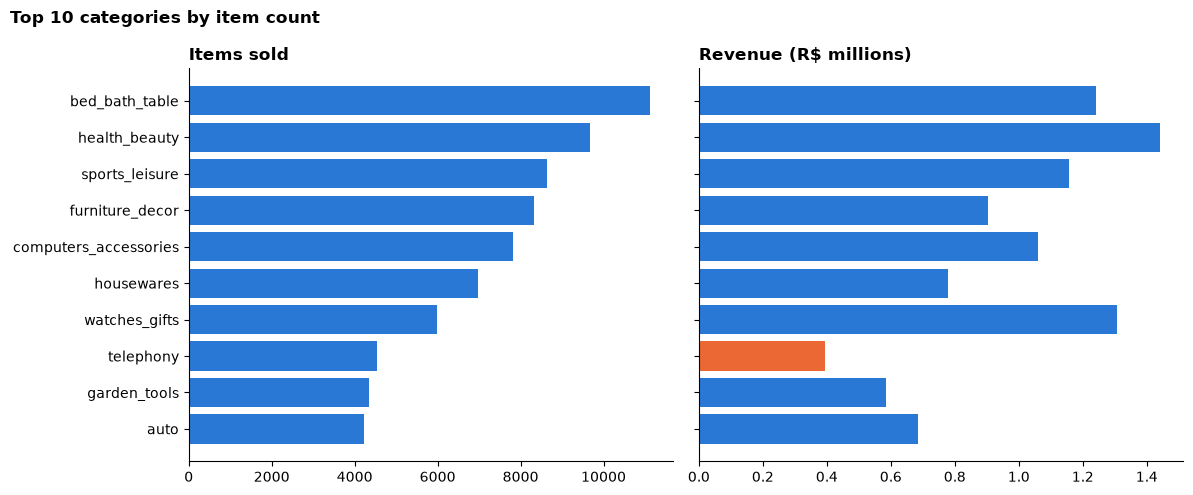

In [7]:
# Two panels sharing the category axis, instead of one chart with two y-scales
order = top_items.index[::-1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ax1.barh(order, top_items.loc[order, "items"], color=BLUE)
ax1.set_title("Items sold", loc="left", fontweight="bold")
ax2.barh(order, top_items.loc[order, "revenue"] / 1e6,
         color=[ORANGE if c == "telephony" else BLUE for c in order])
ax2.set_title("Revenue (R$ millions)", loc="left", fontweight="bold")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Top 10 categories by item count", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Answer:** Mostly yes, but not in the same order. Nine of the ten categories that sell the most items are also in the top ten by revenue.
- **bed_bath_table** sells the most items (11,115) but is 3rd by revenue; **health_beauty** is 1st by revenue.
- **watches_gifts** is only 7th by items but 2nd by revenue, because watches are expensive.
- **telephony** is 8th by items but only 14th by revenue (many cheap accessories). **cool_stuff** takes its place in the revenue top 10.

So item count shows popularity, not value, and the dashboard needs both measures side by side.

### A3. Monthly trend of unique orders: is there seasonality?

In [8]:
sales_master["order_month"] = pd.to_datetime(sales_master["order_purchase_timestamp"]).dt.to_period("M")
monthly = sales_master.groupby("order_month").agg(
    unique_orders=("order_id", "nunique"),   # Distinct Count in Power BI
    item_rows=("order_id", "size"),          # what a plain Count would show
)
print(monthly)

             unique_orders  item_rows
order_month                          
2016-09                  3          6
2016-10                308        363
2016-12                  1          1
2017-01                789        955
2017-02               1733       1951
2017-03               2641       3000
2017-04               2391       2684
2017-05               3660       4136
2017-06               3217       3583
2017-07               3969       4519
2017-08               4293       4910
2017-09               4243       4831
2017-10               4568       5322
2017-11               7451       8665
2017-12               5624       6308
2018-01               7220       8208
2018-02               6694       7672
2018-03               7188       8217
2018-04               6934       7975
2018-05               6853       7925
2018-06               6160       7078
2018-07               6273       7092
2018-08               6452       7248
2018-09                  1          1


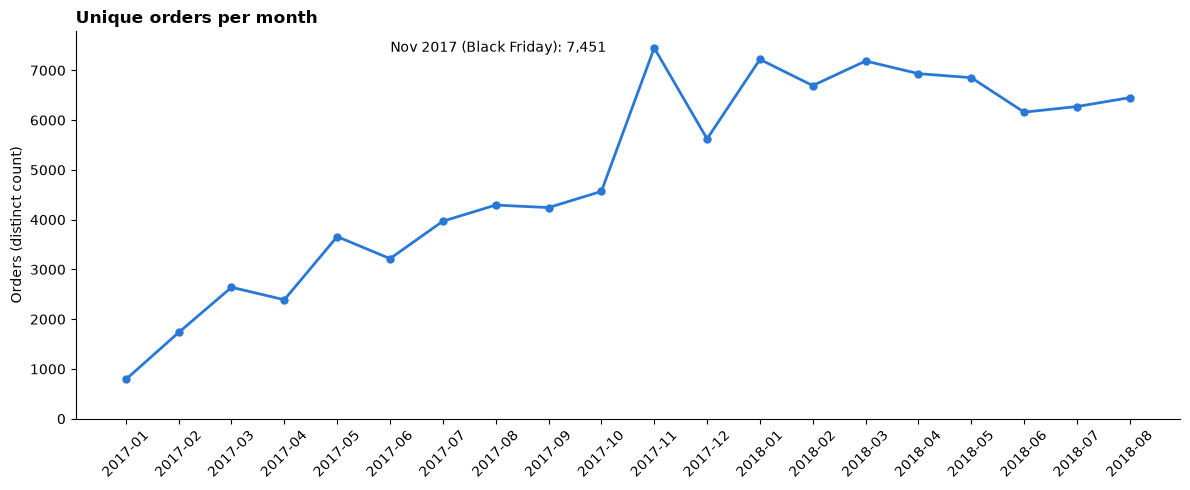

In [9]:
# Sep-Dec 2016 and Sep 2018 have only a handful of orders (start/end of data
# collection), so I chart Jan 2017 - Aug 2018 only.
trend = monthly.loc["2017-01":"2018-08", "unique_orders"]
x = trend.index.astype(str)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x, trend.values, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.annotate(f"Nov 2017 (Black Friday): {trend.max():,}", xy=(str(trend.idxmax()), trend.max()),
            xytext=(-190, 0), textcoords="offset points", va="center")
ax.set_title("Unique orders per month", loc="left", fontweight="bold")
ax.set_ylabel("Orders (distinct count)")
ax.set_ylim(0)
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Answer:** Orders grew steeply through 2017, from 789 in January to about 4,500 a month by October. **November 2017 is the clear peak (7,451 orders)** because of Black Friday. From January 2018 orders level off at about 6,000–7,200 a month. With less than two full years of data I can't confirm a yearly cycle, but the November spike is a clear seasonal effect.

A plain Count of rows would overstate every month, because orders with several items appear several times (`item_rows` vs `unique_orders` above). That's why Power BI needs **Distinct Count** of `order_id`.

## 5. Group B: Customer Experience and Deliveries

### B1. Which states have the lowest average review score?

                avg_score  reviews
customer_state                    
RR                   3.61       46
AL                   3.75      414
MA                   3.76      746
SE                   3.81      349
PA                   3.85      968
CE                   3.85     1329
BA                   3.86     3357
RJ                   3.87    12765
PI                   3.92      491
PE                   4.01     1646

Overall average: 4.09


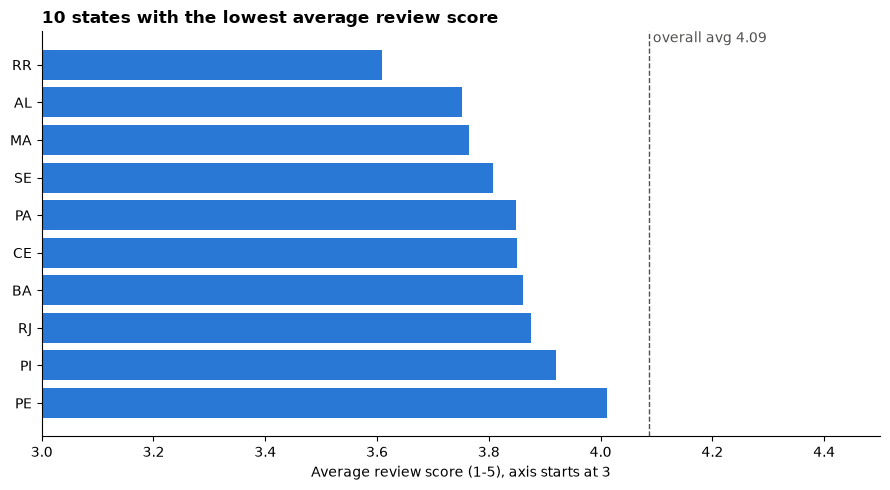

In [10]:
state_score = (reviews_master.groupby("customer_state")["review_score"]
               .agg(avg_score="mean", reviews="size")
               .sort_values("avg_score"))
overall = reviews_master["review_score"].mean()
print(state_score.round(2).head(10))
print(f"\nOverall average: {overall:.2f}")

lowest = state_score.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(lowest.index, lowest["avg_score"], color=BLUE)
ax.axvline(overall, color="#52514e", linestyle="--", linewidth=1)
ax.text(overall, 9.6, f" overall avg {overall:.2f}", color="#52514e")
ax.set_xlim(3, 4.5)
ax.set_title("10 states with the lowest average review score", loc="left", fontweight="bold")
ax.set_xlabel("Average review score (1-5), axis starts at 3")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Answer:** **Roraima (RR, 3.61)**, Alagoas (AL, 3.75), Maranhão (MA, 3.76), Sergipe (SE, 3.81) and Pará (PA, 3.85) have the lowest averages, all in the North and Northeast. RR has only 46 reviews, so its average is less reliable. Rio de Janeiro (3.87) is the only large market in the bottom ten; with 12,765 reviews it is the biggest problem area. These states are far from the São Paulo sellers, which points to delivery as a cause (checked in B3).

### B2. Distribution of review scores

              reviews  percent
review_score                  
1               11424     11.5
2                3151      3.2
3                8179      8.2
4               19142     19.3
5               57328     57.8


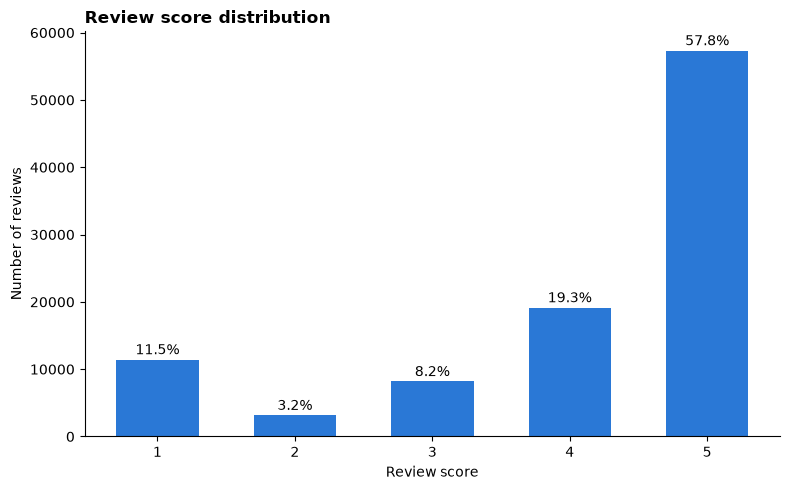

In [11]:
dist = reviews_master["review_score"].value_counts().sort_index()
pct = dist / dist.sum() * 100
print(pd.DataFrame({"reviews": dist, "percent": pct.round(1)}))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(dist.index, dist.values, color=BLUE, width=0.6)
for b, p in zip(bars, pct):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 800, f"{p:.1f}%", ha="center")
ax.set_title("Review score distribution", loc="left", fontweight="bold")
ax.set_xlabel("Review score")
ax.set_ylabel("Number of reviews")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Answer:** Most customers are happy: **57.8% give 5 stars** and 77% give 4 or 5. But the distribution is U-shaped: **11.5% give 1 star**, slightly more than the 2-star and 3-star reviews combined (11.4%). Unhappy customers tend to pick the lowest score rather than a middle one.

### B3. Is there a relationship between delivery delays and satisfaction?
**Delay (days)** = delivered date − estimated delivery date, in calendar days. Negative means it arrived early. Orders that were never delivered have no delay and are left out.

In [12]:
delivered = pd.to_datetime(reviews_master["order_delivered_customer_date"]).dt.normalize()
estimated = pd.to_datetime(reviews_master["order_estimated_delivery_date"]).dt.normalize()
reviews_master["delay_days"] = (delivered - estimated).dt.days

print("Reviews with no delivery date:", reviews_master["delay_days"].isna().sum())
has_delay = reviews_master.dropna(subset=["delay_days"]).copy()

has_delay["delivery_status"] = pd.cut(
    has_delay["delay_days"],
    bins=[-1000, -15, -8, -1, 0, 7, 14, 1000],
    labels=["15+ days early", "8-14 days early", "1-7 days early", "On time",
            "1-7 days late", "8-14 days late", "15+ days late"],
)
by_status = has_delay.groupby("delivery_status", observed=True)["review_score"].agg(
    avg_score="mean", reviews="size")
print(by_status.round(2))

late = has_delay["delay_days"] > 0
print(f"\nLate: {late.mean()*100:.1f}% of delivered orders, avg score {has_delay.loc[late, 'review_score'].mean():.2f}")
print(f"On time or early: avg score {has_delay.loc[~late, 'review_score'].mean():.2f}")
print(f"Correlation (delay vs score): {has_delay['delay_days'].corr(has_delay['review_score']):.2f}")

Reviews with no delivery date: 2865
                 avg_score  reviews
delivery_status                    
15+ days early        4.32    34983
8-14 days early       4.31    36356
1-7 days early        4.20    17319
On time               4.03     1291
1-7 days late         2.71     3612
8-14 days late        1.68     1453
15+ days late         1.72     1345

Late: 6.7% of delivered orders, avg score 2.27
On time or early: avg score 4.29
Correlation (delay vs score): -0.27


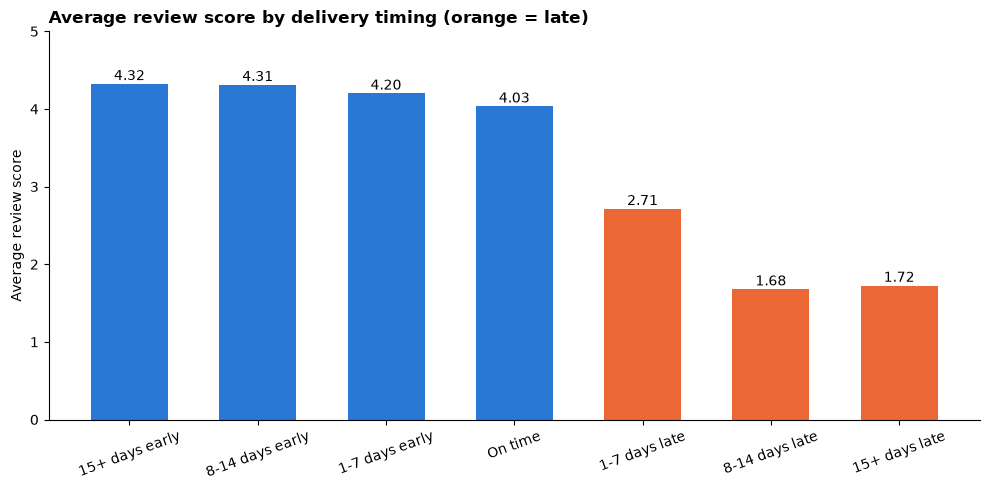

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = by_status.index.astype(str)
bars = ax.bar(labels, by_status["avg_score"], width=0.6,
              color=[ORANGE if "late" in l else BLUE for l in labels])
for b, v in zip(bars, by_status["avg_score"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f"{v:.2f}", ha="center")
ax.set_ylim(0, 5)
ax.set_title("Average review score by delivery timing (orange = late)", loc="left", fontweight="bold")
ax.set_ylabel("Average review score")
ax.tick_params(axis="x", rotation=20)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Answer:** Yes, and it is the strongest pattern in this assignment. Orders that arrive early average **about 4.2–4.3 stars**. Once an order is late, satisfaction collapses: **2.71 stars at 1–7 days late, and about 1.7 at 8+ days late**.

The correlation is only about −0.27 because most orders arrive well before the estimate. The effect isn't a straight line; it's a sharp drop once the promised date is missed. Business lesson: keeping the delivery promise matters much more than delivering extra early.

## 6. Summary for the Dashboard
| Page | Question | Key finding |
|---|---|---|
| Sales | A1 Revenue by state | SP ≈ 37% of revenue, ~3× RJ |
| Sales | A2 Items vs revenue | 9 of top 10 overlap; watches_gifts is high value, telephony low value |
| Sales | A3 Monthly orders | Strong 2017 growth, Black Friday peak in Nov 2017, plateau in 2018 |
| Customer | B1 Lowest-rated states | RR, AL, MA, SE, PA (North/Northeast); RJ is the largest weak market |
| Customer | B2 Score distribution | 58% five-star, but 11.5% one-star (U-shape) |
| Customer | B3 Delay vs score | Late orders drop from ~4.2 to ~1.7–2.7 stars |